In [2]:
import numpy as np
import scipy as sp
import sympy as smp
import matplotlib.pyplot as plt
import random

import qiskit

import sys
sys.path.insert(0, '../../')

import oasis_dla
import pennylane as qp
from oasis_dla import X, Y, Z

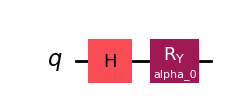

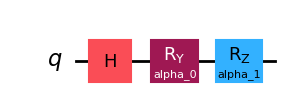

In [6]:
vqls_ry = oasis_dla.VQLS(qubits=1, ansatz_type=0, cost='direct')
vqls_rz = oasis_dla.VQLS(qubits=1, ansatz_type=1, cost='direct')

display(vqls_ry.ansatz.draw('mpl'))
display(vqls_rz.ansatz.draw('mpl'))

In [ ]:
generators = oasis_dla.extract_generators(vqls_ry.ansatz)

dla_ry = oasis_dla.construct_dla(generators)
dla_ry

print(f"Generators: \n{generators}")
print(f"DLA: \n{dla_ry}")
print(f"Pennylane DLA: \n{pennylane_dla}")
print(f"dim g_ry = {len(dla_ry)}")



Generators: 
[array([[-0.70710678+0.j,  0.70710678+0.j],
       [ 0.70710678+0.j,  0.70710678+0.j]]), array([[ 0. +0.j, -0.5+0.j],
       [ 0.5+0.j,  0. +0.j]])]
DLA: 
[array([[-0.70710678+0.j,  0.70710678+0.j],
       [ 0.70710678+0.j,  0.70710678+0.j]]), array([[ 0. +0.j, -0.5+0.j],
       [ 0.5+0.j,  0. +0.j]]), array([[ 0.70710678+0.j,  0.70710678+0.j],
       [ 0.70710678+0.j, -0.70710678+0.j]])]
Pennylane DLA: 
[Y(0)]
dim g_ry = 3


In [ ]:
generators = oasis_dla.extract_generators(vqls_rz.ansatz)

dla_rz = oasis_dla.fast_numerical_construct_dla(generators)
print(f"fast closure algorithm: DLA_rz = {dla_rz}")
print(f"dim g_rz = {len(dla_rz)}")


NameError: name 'oasis_dla' is not defined

Closure test:

for two different dla's that I got, the one using the fast numerical generation paper and the one from the diagnosing BP paper, I'll compute closure to check which ones right

In [ ]:
# fast numerical lie closure

dla = oasis_dla.fast_numerical_construct_dla(generators)
dla

vecs = [m.flatten() for m in dla]
mat = np.column_stack(vecs)
basis_rank = np.linalg.matrix_rank(mat)
print(f"Rank of basis vector matrix: {basis_rank}")

closure = dla.copy()
for g1 in dla:
    for g2 in dla:
        closure.append(oasis_dla.commutator(g1, g2))


vecs = [m.flatten() for m in closure]
new_mat = np.column_stack(vecs)
new_rank = np.linalg.matrix_rank(new_mat)
print(f"Rank of new vector matrix: {new_rank}")

Rank of basis vector matrix: 3
Rank of new vector matrix: 3


Now that we know we have the right DLA (which is all of su(2) itself), lets compute two things
- $P_\mathfrak{g}(\rho)$
- $Ann_\mathfrak{g}(|b\rangle)$

where $\rho = |b\rangle \langle b|$

In [ ]:
# g-purity first

# hilbert-schmidt inner product
def inner_product(A, B):
    return np.trace(A.conj().T @ B)

# ρ = O in the case of VQLS since the state being measured against |ψ> is |b>
b = (np.ones(2) / np.sqrt(2)).reshape(-1, 1)
rho = b @ b.T.conj()
O = rho
print(f"ρ = \n{rho}")

# complexify the DLA first
i_dla_ry = []
for g in dla_ry:
    i_dla_ry.append(g + 1j *g)

print(f"g + ig = \n{i_dla_ry}")

# compute g-purity
def g_purity(g, H):
    gpurity = 0
    for B in g:
        gpurity += (inner_product(B, H))**2
        print
    return gpurity

Pg_rho = g_purity(i_dla_ry, rho)
Pg_O = g_purity(i_dla_ry, O)
print(f"g-Purity of ρ: {Pg_rho}")
print(f"g-Purity of O: {Pg_O}")
print(f"dim_g = {len(dla_ry)}")

Var_l = (Pg_rho * Pg_O) / len(dla_ry)
print(f"Variance of the loss function: {Var_l}")

ρ = 
[[0.5 0.5]
 [0.5 0.5]]
g + ig = 
[array([[-0.70710678-0.70710678j,  0.70710678+0.70710678j],
       [ 0.70710678+0.70710678j,  0.70710678+0.70710678j]]), array([[ 0. +0.j , -0.5-0.5j],
       [ 0.5+0.5j,  0. +0.j ]]), array([[ 0.70710678+0.70710678j,  0.70710678+0.70710678j],
       [ 0.70710678+0.70710678j, -0.70710678-0.70710678j]])]
g-Purity of ρ: -1.9999999999999991j
g-Purity of O: -1.9999999999999991j
dim_g = 3
Variance of the loss function: (-1.3333333333333321+0j)


In [ ]:
g = [(1j/np.sqrt(2)) * (X - Z), 1j/2 * Y, 1j/2 * Z]
print(g)
gp = g_purity(g, rho)
gp

[array([[-0.-0.70710678j,  0.+0.70710678j],
       [ 0.+0.70710678j,  0.+0.70710678j]]), array([[ 0. +0.j,  0.5-0.j],
       [-0.5+0.j,  0. +0.j]]), array([[ 0.+0.5j,  0.+0.j ],
       [ 0.+0.j , -0.-0.5j]])]


np.complex128(-0.4999999999999998+0j)

In [ ]:
# annihilator of rho in g

# get the matrix of all actions
actions = [g @ b for g in dla_ry]
for a in actions:
    print(a,"\n")
M = np.column_stack(actions)

nullspace = sp.linalg.null_space(M)
print(f"Nullspace: \n{nullspace}")

print(np.linalg.matrix_rank(M), nullspace.shape[1])

ci = nullspace.reshape(1, -1)[0]

# spanned by 1 vector
ann_g_basis = sum([c * g for c, g in zip(ci, dla_ry)])
print(ann_g_basis)

np.allclose((random_r() * ann_g_basis) @ b, 0)

[[0.+0.j]
 [1.+0.j]] 

[[-0.35355339+0.j]
 [ 0.35355339+0.j]] 

[[1.+0.j]
 [0.+0.j]] 

Nullspace: 
[[-0.31622777-0.j]
 [ 0.89442719-0.j]
 [ 0.31622777-0.j]]
2 1
[[ 0.4472136+0.j -0.4472136+0.j]
 [ 0.4472136+0.j -0.4472136+0.j]]


NameError: name 'random_r' is not defined

In [ ]:
# inner_product(, rho)
inner_product(1j/2 * Y, rho)

Ry = 1j/2 * Y
H = (1j/np.sqrt(2)) * (X - Z)

np.trace(abs(H.conj().T @ rho))
# np.trace(Ry.conj().T @ rho)**2

NameError: name 'Y' is not defined